In [2]:
# Eye Tracking Data Statistics
# Load libraries and data for fixation analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys

# Add project root to path
sys.path.append('~/Code/Eye_EEG')
from data.data_configs import SELECTED_ET_DATA_DIR
from data.data_loader import DataLoader

print("📊 Eye Tracking Data Statistics Analysis")
print("=" * 50)

📊 Eye Tracking Data Statistics Analysis


In [3]:
# Load fixation summary for selected subjects
fixation_summary_path = SELECTED_ET_DATA_DIR / "fixation_summary_all.csv"
print(f"Loading fixation summary from: {fixation_summary_path}")

fixation_summary = pd.read_csv(fixation_summary_path, dtype={"stimulus": str})
print(f"✅ Loaded fixation summary: {fixation_summary.shape[0]} rows, {fixation_summary.shape[1]} columns")

# Load statistics on selected subjects
stats_path = SELECTED_ET_DATA_DIR / "selected_et_statistics.csv" 
stats_df = pd.read_csv(stats_path)
print(f"✅ Loaded subject statistics: {stats_df.shape[0]} subjects")

print("\nSelected subjects:")
print(stats_df['subject'].tolist())

Loading fixation summary from: ~/Code/Eye_EEG/data/data/labeled_et_data/selected/fixation_summary_all.csv
✅ Loaded fixation summary: 3250 rows, 8 columns
✅ Loaded subject statistics: 13 subjects

Selected subjects:
['P01', 'P07', 'P09', 'P10', 'P16', 'P17', 'P20', 'P21', 'P27', 'P28', 'P30', 'P34', 'P38']


In [4]:
# Load eye tracking event data for detailed fixation analysis
print("Loading detailed fixation data...")

all_fixations = []
subjects = stats_df['subject'].tolist()

for subject in subjects:
    events_path = SELECTED_ET_DATA_DIR / f"{subject}_labeled_events.csv"
    if events_path.exists():
        df = pd.read_csv(events_path, dtype={"stimulus": str})
        # Filter to fixations only
        fixations = df[df['event_type'] == 'Fixation'].copy()
        fixations['subject'] = subject
        all_fixations.append(fixations)
        print(f"✅ {subject}: {len(fixations)} fixations")
    else:
        print(f"❌ {subject}: No events file found")

# Combine all fixations
fixations_df = pd.concat(all_fixations, ignore_index=True)
print(f"\n🎯 Total fixations loaded: {len(fixations_df)}")
print(f"Subjects with data: {fixations_df['subject'].nunique()}")
print(f"Unique stimuli: {fixations_df['stimulus'].nunique()}")

Loading detailed fixation data...
✅ P01: 2452 fixations
✅ P07: 2509 fixations
✅ P09: 2218 fixations
✅ P10: 2646 fixations
✅ P16: 2829 fixations
✅ P17: 3051 fixations
✅ P20: 2487 fixations
✅ P21: 3085 fixations
✅ P27: 2675 fixations
✅ P28: 2121 fixations
✅ P30: 2193 fixations
✅ P34: 2673 fixations
✅ P38: 2073 fixations

🎯 Total fixations loaded: 33012
Subjects with data: 13
Unique stimuli: 886


In [5]:
# Overall fixation statistics
print("🎯 OVERALL FIXATION STATISTICS")
print("=" * 40)

# Total fixation counts
total_fixations = len(fixations_df)
on_airplane = (fixations_df['fixation_on_airplane'] == True).sum()
off_airplane = (fixations_df['fixation_on_airplane'] == False).sum()

print(f"Total fixations: {total_fixations:,}")
print(f"Fixations ON airplane: {on_airplane:,} ({on_airplane/total_fixations*100:.1f}%)")
print(f"Fixations OFF airplane: {off_airplane:,} ({off_airplane/total_fixations*100:.1f}%)")

# Verify counts match
assert on_airplane + off_airplane == total_fixations, "Fixation counts don't match!"
print("✅ Counts verified")

# Average fixations per subject
avg_per_subject = total_fixations / len(subjects)
print(f"Average fixations per subject: {avg_per_subject:.1f}")

🎯 OVERALL FIXATION STATISTICS
Total fixations: 33,012
Fixations ON airplane: 18,292 (55.4%)
Fixations OFF airplane: 14,720 (44.6%)
✅ Counts verified
Average fixations per subject: 2539.4


In [6]:
# Per-subject fixation statistics
print("\n👤 PER-SUBJECT FIXATION STATISTICS")
print("=" * 40)

subject_stats = []
for subject in sorted(subjects):
    subj_data = fixations_df[fixations_df['subject'] == subject]
    total_subj = len(subj_data)
    on_subj = (subj_data['fixation_on_airplane'] == True).sum()
    off_subj = (subj_data['fixation_on_airplane'] == False).sum()
    
    subject_stats.append({
        'subject': subject,
        'total_fixations': total_subj,
        'on_airplane': on_subj,
        'off_airplane': off_subj,
        'pct_on_airplane': (on_subj / total_subj * 100) if total_subj > 0 else 0,
        'pct_off_airplane': (off_subj / total_subj * 100) if total_subj > 0 else 0
    })
    
    print(f"{subject}: {total_subj:4d} total | {on_subj:4d} ON ({on_subj/total_subj*100:5.1f}%) | {off_subj:4d} OFF ({off_subj/total_subj*100:5.1f}%)")

# Convert to DataFrame for easier analysis
subject_stats_df = pd.DataFrame(subject_stats)
print(f"\n📊 Summary across {len(subjects)} subjects:")
print(f"Mean fixations per subject: {subject_stats_df['total_fixations'].mean():.1f} ± {subject_stats_df['total_fixations'].std():.1f}")
print(f"Mean % ON airplane: {subject_stats_df['pct_on_airplane'].mean():.1f}% ± {subject_stats_df['pct_on_airplane'].std():.1f}%")


👤 PER-SUBJECT FIXATION STATISTICS
P01: 2452 total | 1257 ON ( 51.3%) | 1195 OFF ( 48.7%)
P07: 2509 total | 1391 ON ( 55.4%) | 1118 OFF ( 44.6%)
P09: 2218 total | 1137 ON ( 51.3%) | 1081 OFF ( 48.7%)
P10: 2646 total | 1490 ON ( 56.3%) | 1156 OFF ( 43.7%)
P16: 2829 total | 1785 ON ( 63.1%) | 1044 OFF ( 36.9%)
P17: 3051 total | 1803 ON ( 59.1%) | 1248 OFF ( 40.9%)
P20: 2487 total | 1306 ON ( 52.5%) | 1181 OFF ( 47.5%)
P21: 3085 total | 1716 ON ( 55.6%) | 1369 OFF ( 44.4%)
P27: 2675 total | 1526 ON ( 57.0%) | 1149 OFF ( 43.0%)
P28: 2121 total | 1062 ON ( 50.1%) | 1059 OFF ( 49.9%)
P30: 2193 total | 1275 ON ( 58.1%) |  918 OFF ( 41.9%)
P34: 2673 total | 1439 ON ( 53.8%) | 1234 OFF ( 46.2%)
P38: 2073 total | 1105 ON ( 53.3%) |  968 OFF ( 46.7%)

📊 Summary across 13 subjects:
Mean fixations per subject: 2539.4 ± 331.4
Mean % ON airplane: 55.2% ± 3.7%


In [7]:
# Object Detection Rate Analysis
print("\n✈️ OBJECT DETECTION RATE ANALYSIS")
print("=" * 40)

# Calculate detection rates from fixation summary
print("Detection rates from fixation summary:")

# Overall detection across all trials
total_airplanes = fixation_summary['n_airplanes'].sum()
total_detected = fixation_summary['n_fixated_airplanes'].sum()
overall_detection_rate = (total_detected / total_airplanes * 100) if total_airplanes > 0 else 0

print(f"Total airplanes across all trials: {total_airplanes:,}")
print(f"Total airplanes fixated: {total_detected:,}")
print(f"Overall detection rate: {overall_detection_rate:.1f}%")

# Per-subject detection rates
print(f"\nPer-subject detection rates:")
subject_detection_rates = []
for subject in sorted(subjects):
    subj_summary = fixation_summary[fixation_summary['subject'] == subject]
    
    subj_total_planes = subj_summary['n_airplanes'].sum()
    subj_detected_planes = subj_summary['n_fixated_airplanes'].sum()
    subj_detection_rate = (subj_detected_planes / subj_total_planes * 100) if subj_total_planes > 0 else 0
    
    subject_detection_rates.append({
        'subject': subject,
        'total_airplanes': subj_total_planes,
        'detected_airplanes': subj_detected_planes,
        'detection_rate_pct': subj_detection_rate
    })
    
    print(f"{subject}: {subj_detected_planes:3d}/{subj_total_planes:3d} airplanes detected ({subj_detection_rate:5.1f}%)")

# Summary statistics
detection_df = pd.DataFrame(subject_detection_rates)
print(f"\n📊 Detection rate summary:")
print(f"Mean detection rate: {detection_df['detection_rate_pct'].mean():.1f}% ± {detection_df['detection_rate_pct'].std():.1f}%")
print(f"Range: {detection_df['detection_rate_pct'].min():.1f}% - {detection_df['detection_rate_pct'].max():.1f}%")


✈️ OBJECT DETECTION RATE ANALYSIS
Detection rates from fixation summary:
Total airplanes across all trials: 5,926
Total airplanes fixated: 5,926
Overall detection rate: 100.0%

Per-subject detection rates:
P01: 419/419 airplanes detected (100.0%)
P07: 517/517 airplanes detected (100.0%)
P09: 463/463 airplanes detected (100.0%)
P10: 466/466 airplanes detected (100.0%)
P16: 543/543 airplanes detected (100.0%)
P17: 475/475 airplanes detected (100.0%)
P20: 412/412 airplanes detected (100.0%)
P21: 424/424 airplanes detected (100.0%)
P27: 459/459 airplanes detected (100.0%)
P28: 391/391 airplanes detected (100.0%)
P30: 526/526 airplanes detected (100.0%)
P34: 399/399 airplanes detected (100.0%)
P38: 432/432 airplanes detected (100.0%)

📊 Detection rate summary:
Mean detection rate: 100.0% ± 0.0%
Range: 100.0% - 100.0%



📈 CREATING VISUALIZATIONS


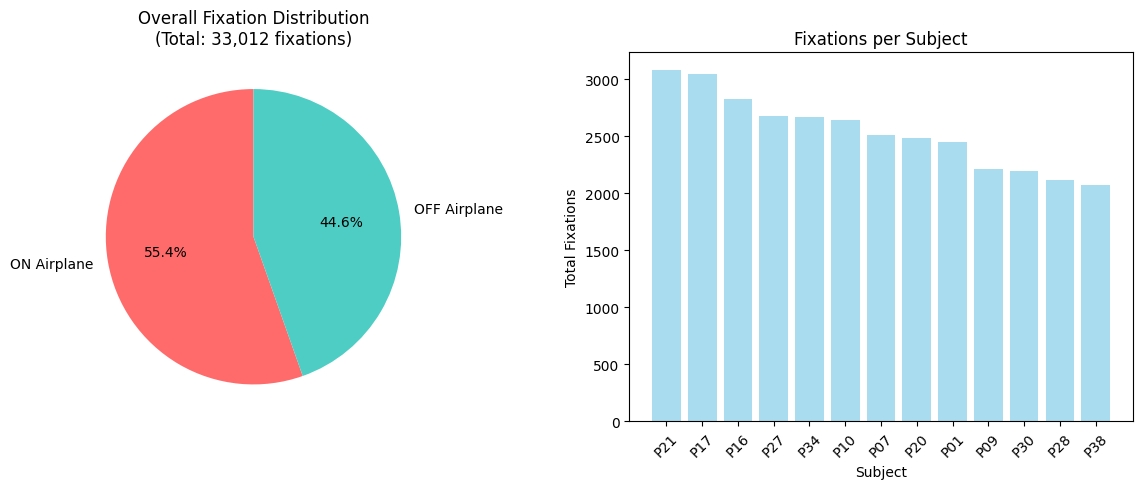

✅ Figure 1: Overall fixation statistics


In [8]:
# Visualizations
print("\n📈 CREATING VISUALIZATIONS")
print("=" * 30)

# Set up plotting style
plt.style.use('default')
sns.set_palette("husl")

# Figure 1: Overall fixation distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Pie chart of overall fixations
labels = ['ON Airplane', 'OFF Airplane']
sizes = [on_airplane, off_airplane]
colors = ['#ff6b6b', '#4ecdc4']
ax1.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, colors=colors)
ax1.set_title(f'Overall Fixation Distribution\n(Total: {total_fixations:,} fixations)')

# Bar chart per subject
subject_stats_df_sorted = subject_stats_df.sort_values('total_fixations', ascending=False)
x_pos = range(len(subject_stats_df_sorted))
ax2.bar(x_pos, subject_stats_df_sorted['total_fixations'], color='skyblue', alpha=0.7)
ax2.set_xlabel('Subject')
ax2.set_ylabel('Total Fixations')
ax2.set_title('Fixations per Subject')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(subject_stats_df_sorted['subject'], rotation=45)

plt.tight_layout()
plt.show()

print("✅ Figure 1: Overall fixation statistics")

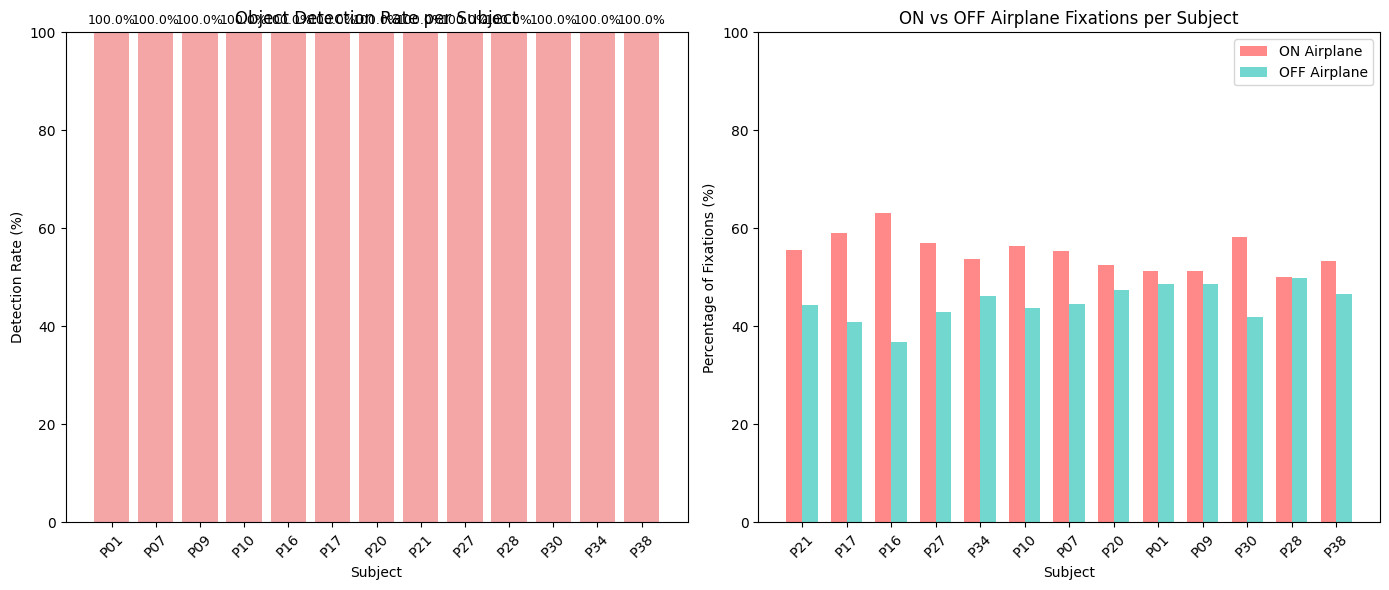

✅ Figure 2: Detection rates and subject comparison


In [9]:
# Figure 2: Detection rates and subject comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Detection rates per subject
detection_df_sorted = detection_df.sort_values('detection_rate_pct', ascending=False)
x_pos = range(len(detection_df_sorted))
bars = ax1.bar(x_pos, detection_df_sorted['detection_rate_pct'], color='lightcoral', alpha=0.7)
ax1.set_xlabel('Subject')
ax1.set_ylabel('Detection Rate (%)')
ax1.set_title('Object Detection Rate per Subject')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(detection_df_sorted['subject'], rotation=45)
ax1.set_ylim(0, 100)

# Add value labels on bars
for i, bar in enumerate(bars):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 1,
             f'{height:.1f}%', ha='center', va='bottom', fontsize=9)

# Percentage ON/OFF airplane per subject  
width = 0.35
x_pos2 = np.arange(len(subject_stats_df_sorted))
ax2.bar(x_pos2 - width/2, subject_stats_df_sorted['pct_on_airplane'], width, 
        label='ON Airplane', color='#ff6b6b', alpha=0.8)
ax2.bar(x_pos2 + width/2, subject_stats_df_sorted['pct_off_airplane'], width,
        label='OFF Airplane', color='#4ecdc4', alpha=0.8)

ax2.set_xlabel('Subject')
ax2.set_ylabel('Percentage of Fixations (%)')
ax2.set_title('ON vs OFF Airplane Fixations per Subject')
ax2.set_xticks(x_pos2)
ax2.set_xticklabels(subject_stats_df_sorted['subject'], rotation=45)
ax2.legend()
ax2.set_ylim(0, 100)

plt.tight_layout()
plt.show()

print("✅ Figure 2: Detection rates and subject comparison")

In [10]:
# Summary tables for export
print("\n📋 SUMMARY TABLES")
print("=" * 20)

print("\n1. Subject Fixation Statistics:")
print(subject_stats_df.round(1))

print("\n2. Subject Detection Rates:") 
print(detection_df.round(1))

print("\n3. Overall Summary:")
summary_stats = {
    'Total Subjects': len(subjects),
    'Total Fixations': f"{total_fixations:,}",
    'Fixations ON Airplane': f"{on_airplane:,} ({on_airplane/total_fixations*100:.1f}%)",
    'Fixations OFF Airplane': f"{off_airplane:,} ({off_airplane/total_fixations*100:.1f}%)",
    'Overall Object Detection Rate': f"{overall_detection_rate:.1f}%",
    'Mean Fixations per Subject': f"{subject_stats_df['total_fixations'].mean():.1f}",
    'Mean Detection Rate': f"{detection_df['detection_rate_pct'].mean():.1f}%"
}

for key, value in summary_stats.items():
    print(f"{key}: {value}")

print(f"\n✅ Analysis complete! Data loaded from {len(subjects)} subjects with {total_fixations:,} total fixations.")


📋 SUMMARY TABLES

1. Subject Fixation Statistics:
   subject  total_fixations  on_airplane  off_airplane  pct_on_airplane  \
0      P01             2452         1257          1195             51.3   
1      P07             2509         1391          1118             55.4   
2      P09             2218         1137          1081             51.3   
3      P10             2646         1490          1156             56.3   
4      P16             2829         1785          1044             63.1   
5      P17             3051         1803          1248             59.1   
6      P20             2487         1306          1181             52.5   
7      P21             3085         1716          1369             55.6   
8      P27             2675         1526          1149             57.0   
9      P28             2121         1062          1059             50.1   
10     P30             2193         1275           918             58.1   
11     P34             2673         1439         